## 0. IMPORTS:
---

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp

## 1. LEITURA DO SINAL:
---

In [16]:
#Primeiro vamos fazer a definição dos parâmetros do Sistema

#Taxa de amostragem, definida em Hz#
fs = 48000
#Frequência de simbolos, em simbolos por segundo#
Rs = 1000
#Excesso de banda#
b = 0.35
#Portadoras dos 5 canais do sinal#
portadoras = [5000, 6500, 8000, 9500, 11000]
#Portadora designada#
fc = 6500
#Fase da portadora designada#
phi = -1.800
#Nome do arquivo designado#
arq  ="canal_G01.csv"


### 1.1. Grandezas derivadas:
---

In [17]:
# Meia banda: Define os limites exatos onde o código integra a PSD para medir a potência de cada canal na Etapa 1
meia_banda = (1.0 + b) * Rs / 2.0
#Espaçamento: Define a distancia entre as portadoras
espacamento = portadoras[1] - portadoras[0]
#Borda vizinha: Define o começo da zona de rejeição
borda_vizinha = espacamento - meia_banda

### 1.2 Leitura do sinal r[n]:
---

In [18]:
#leitura do CSV e criação do indice para o discreto
r = np.loadtxt(arq)
n = np.arange(len(r))

## 2. ANÁLISE ESPECTRAL E DIFERENÇA DE POTÊNCIA:
---

In [19]:
#Para não repetir muito quando for calcular a FFT, uma função foi definida para realizar esse trabalho
def calcular_espectro_fft(x, fs):
    N = len(x)
    #Utilizei a rfft para pegar somente a parte real do sinal, que será ele todo já que é um sinal real
    X = np.fft.rfft(x)
    #Constroi um vetor que corresponde a rfft, em Hertz utilizando o périodo de amostragem (d) 
    f = np.fft.rfftfreq(N, d= (1.0/fs))
    #Calculando a magnitude da FFT
    mag = np.abs(X)/N
    #Convertendo a magnitude para escala dB
    mag_db= 20*np.log10(mag + 1e-15) #o 1e-15 está ai para evitar que no vetor em db tenha -infinito

    return f,mag,mag_db

#realizando o Calculo do espectro do sinal r[x]
f_r, mag_r, mag_r_db = calcular_espectro_fft(r, fs)

### 2.1. Potência em cada canal por Parseval:
---

In [20]:
#Dicionario para armazenar as potências de cada canal
potencias_db = {}
for fk in portadoras:
    #Cria um vetor booleando, marcando true para as frequências de cada canal
    mascara_canal = (f_r >= fk - meia_banda) & (f_r <= fk + meia_banda)
    #calculando pela relação de Parseval
    pot_linear = 2.0 * np.sum(mag_r[mascara_canal] ** 2)
    #covertendo de linear par dB
    potencias_db[fk] = 10.0 * np.log10(pot_linear)

### 2.2. Plot:
---

ETAPA 1: Potência por canal
Canal 1 ( 5000.0 Hz) | Potência: -15.93 dB | Dif: +21.24 dB
Canal 2 ( 6500.0 Hz) | Potência: -37.17 dB | Dif:  +0.00 dBCANAL DESIGNADO
Canal 3 ( 8000.0 Hz) | Potência: -16.06 dB | Dif: +21.11 dB
Canal 4 ( 9500.0 Hz) | Potência: -21.93 dB | Dif: +15.24 dB
Canal 5 (11000.0 Hz) | Potência: -24.62 dB | Dif: +12.55 dB


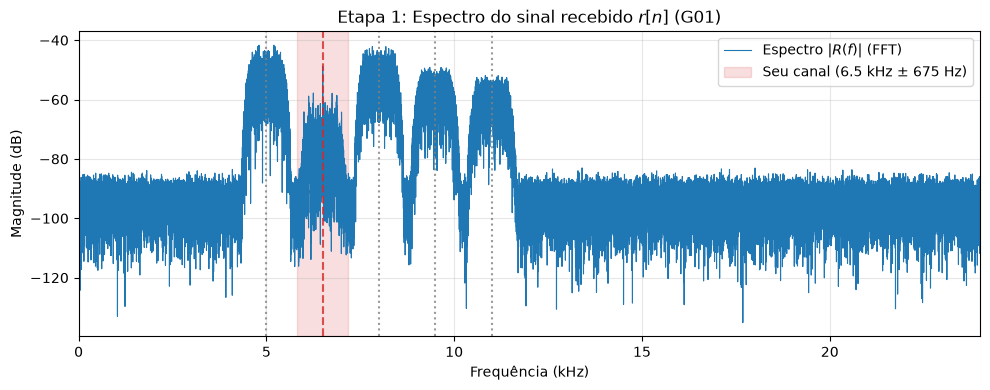

In [21]:
# Comparação de potência entre os 5 canais e o seu canal (fc = 6500 Hz)
pot_meu_canal = potencias_db[fc]
print("ETAPA 1: Potência por canal")

for i, fk in enumerate(portadoras, start=1):
    diff = potencias_db[fk] - pot_meu_canal
    tag = "CANAL DESIGNADO" if fk == fc else ""
    print(f"Canal {i} ({fk:7.1f} Hz) | Potência: {potencias_db[fk]:6.2f} dB | Dif: {diff:+6.2f} dB{tag}")

# Gráfico do espectro recebido r[n]
plt.figure(figsize=(10, 4))
plt.plot(f_r / 1000.0, mag_r_db, lw=0.8, label="Espectro $|R(f)|$ (FFT)")

for fk in portadoras:
    cor = "tab:red" if fk == fc else "gray"
    estilo = "--" if fk == fc else ":"
    plt.axvline(fk / 1000.0, color=cor, ls=estilo, alpha=0.8)

plt.axvspan(
    (fc - meia_banda) / 1000.0,
    (fc + meia_banda) / 1000.0,
    color="tab:red",
    alpha=0.15,
    label=f"Seu canal ({fc/1000:.1f} kHz $\\pm$ {meia_banda:.0f} Hz)",
)
plt.xlabel("Frequência (kHz)")
plt.ylabel("Magnitude (dB)")
plt.title("Etapa 1: Espectro do sinal recebido $r[n]$ (G01)")
plt.xlim(0, fs / 2000.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Trasnslação para banda BASE:
---

### 3.1. Fazendo o deslocamento e calculando o espectro
---

In [22]:
omega_c = 2.0 * np.pi * fc / fs                  # Frequência digital da portadora (rad/amostra)
v = 2.0 * r * np.cos(omega_c * n + phi)          # Translação coerente para 0 Hz

f_v, P_v, P_v_db = calcular_espectro_fft(v, fs)

### 3.2. Plot:
---

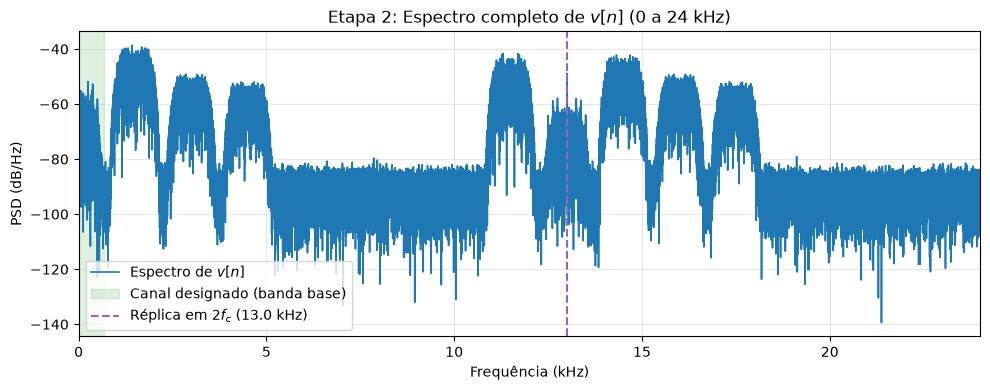

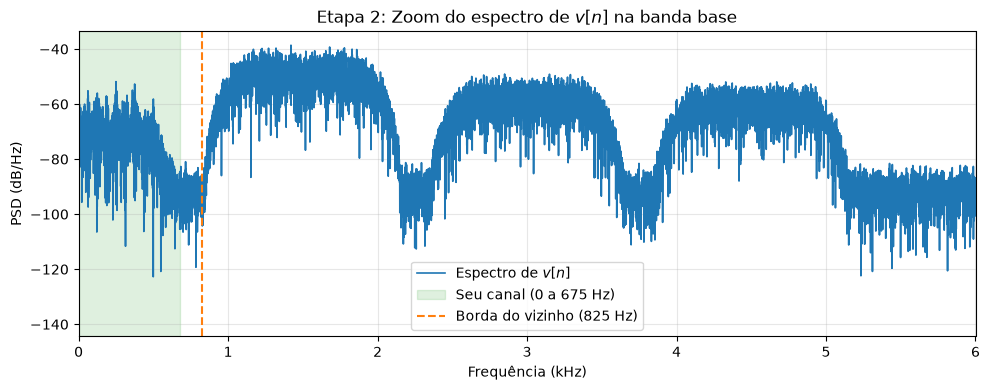

In [23]:
# Gráfico 1: Espectro completo de v[n] (0 a 24 kHz) para ver todas as réplicas
plt.figure(figsize=(10, 4))
plt.plot(f_v / 1000.0, P_v_db, lw=1.2, label="Espectro de $v[n]$")
plt.axvspan(0, meia_banda / 1000.0, color="tab:green", alpha=0.15, label="Canal designado (banda base)")
plt.axvline(2 * fc / 1000.0, color="tab:purple", ls="--", label=f"Réplica em $2f_c$ ({2*fc/1000:.1f} kHz)")
plt.xlabel("Frequência (kHz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Etapa 2: Espectro completo de $v[n]$ (0 a 24 kHz)")
plt.xlim(0, fs / 2000.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Gráfico 2: Zoom em baixa frequência (0 a 6 kHz) para enxergar a banda de guarda
plt.figure(figsize=(10, 4))
plt.plot(f_v / 1000.0, P_v_db, lw=1.2, label="Espectro de $v[n]$")
plt.axvspan(0, meia_banda / 1000.0, color="tab:green", alpha=0.15, label=f"Seu canal (0 a {meia_banda:.0f} Hz)")
plt.axvline(borda_vizinha / 1000.0, color="tab:orange", ls="--", label=f"Borda do vizinho ({borda_vizinha:.0f} Hz)")
plt.xlabel("Frequência (kHz)")
plt.ylabel("PSD (dB/Hz)")
plt.title("Etapa 2: Zoom do espectro de $v[n]$ na banda base")
plt.xlim(0, 6.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()